# Concrete strength exploratory data analysis

[BauLens strength results](../docs/results/strength.md) | [Evaluation protocol](../docs/adr/0003-strength-evaluation-protocol.md)

This notebook describes the UCI Concrete Compressive Strength workbook by I-Cheng Yeh (CC BY 4.0).
It does not fit or select models. The reproducible pipeline lives in `src/baulens/strength/`.
[Dataset and attribution](https://doi.org/10.24432/C5PK67)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from baulens.data.concrete import DEFAULT_CONCRETE_PATH
from baulens.strength.features import INGREDIENTS, TARGET
from baulens.strength.splits import mix_groups, prepare_data

sns.set_theme(style="whitegrid", context="notebook", rc={"figure.dpi": 86})
local_workbook = Path("../data/raw/concrete/Concrete_Data.xls")
workbook = DEFAULT_CONCRETE_PATH if DEFAULT_CONCRETE_PATH.exists() else local_workbook
frame, exact_duplicates = prepare_data(workbook)
groups = mix_groups(frame)
series = frame.assign(mix_id=groups)
age_counts = series.groupby("mix_id")["age_days"].nunique()
same_mix_age = series.groupby(["mix_id", "age_days"])[TARGET].nunique()
print(f"{len(frame) + exact_duplicates:,} source rows, {exact_duplicates} exact duplicates removed")
print(f"{len(frame):,} measurements across {groups.nunique()} exact mix designs")
print(f"{(age_counts > 1).sum()} designs measured at more than one distinct age")
print(f"{(same_mix_age > 1).sum()} mix-age pairs have distinct recorded strengths")

1,030 source rows, 25 exact duplicates removed
1,005 measurements across 428 exact mix designs
182 designs measured at more than one distinct age
9 mix-age pairs have distinct recorded strengths


### Duplicate measurements and the split

Exact duplicates match on all seven ingredients, age and measured strength. They supply no
identifiable independent evidence without specimen or batch IDs. The pipeline retains different
outcomes for the same mix and age. It also keeps every observation of a formulation in one
partition even when the ages differ. Splitting individual rows would allow part of a formulation's
age series to appear during fitting and part during validation.

,Unit,min,25%,50%,75%,max
cement,kg/m³,102.00,190.68,265.0,349.00,540.0
blast_furnace_slag,kg/m³,0.00,0.00,20.0,142.50,359.4
fly_ash,kg/m³,0.00,0.00,0.0,118.27,200.1
water,kg/m³,121.75,166.61,185.7,192.94,247.0
superplasticizer,kg/m³,0.00,0.00,6.1,10.00,32.2
coarse_aggregate,kg/m³,801.00,932.00,968.0,1031.00,1145.0
fine_aggregate,kg/m³,594.00,724.30,780.0,822.20,992.6
age_days,days,1.00,7.00,28.0,56.00,365.0
compressive_strength_mpa,MPa,2.33,23.52,33.8,44.87,82.6


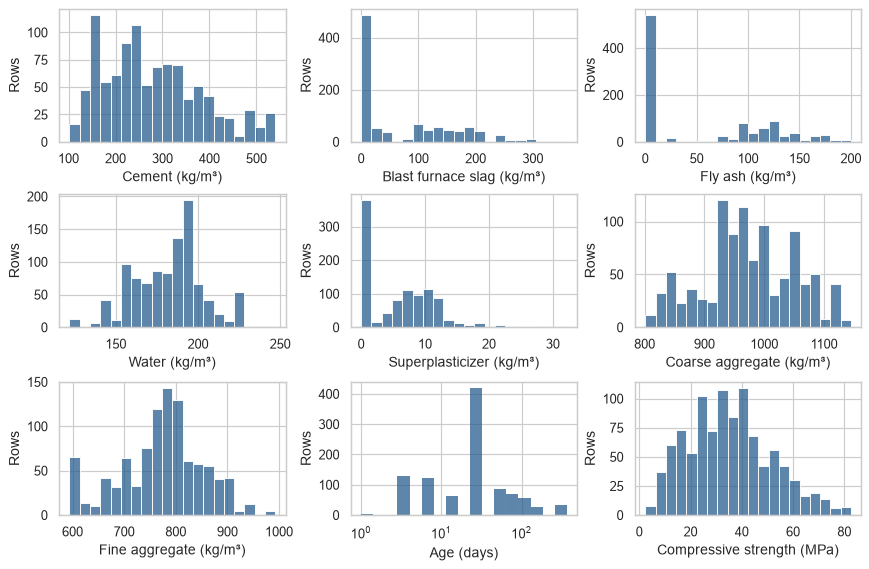

In [2]:
units = dict.fromkeys(INGREDIENTS, "kg/m³")
units.update({"age_days": "days", TARGET: "MPa"})
summary = frame.describe().T.loc[:, ["min", "25%", "50%", "75%", "max"]].round(2)
summary.insert(0, "Unit", pd.Series(units))
display(summary)

fig, axes = plt.subplots(3, 3, figsize=(10, 6.5), layout="constrained")
for name, axis in zip(frame.columns, axes.flat, strict=True):
    if name == "age_days":
        bins = np.geomspace(1, frame[name].max() + 1, 18)
        sns.histplot(frame[name], bins=bins, ax=axis, color="#285e8e")
        axis.set_xscale("log")
    else:
        sns.histplot(frame[name], bins=20, ax=axis, color="#285e8e")
    label = {"age_days": "Age", TARGET: "Compressive strength"}.get(
        name, name.replace("_", " ").capitalize()
    )
    axis.set(xlabel=f"{label} ({units[name]})", ylabel="Rows")
plt.show()

Age is right-skewed and plotted on a log scale. Spikes at zero for slag, fly ash and
superplasticizer represent formulations without those ingredients.

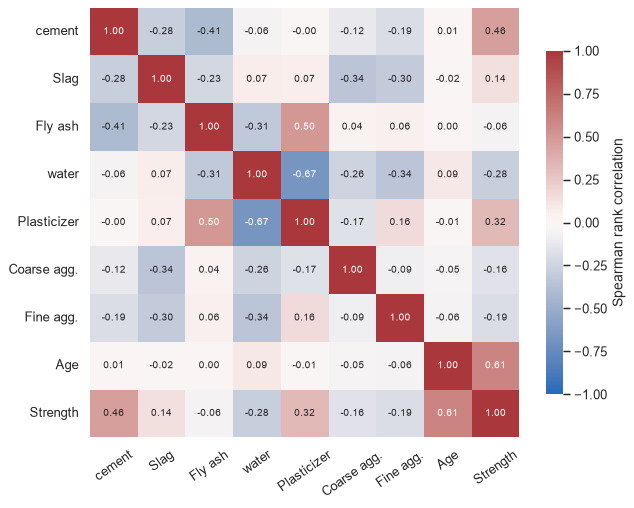

In [3]:
labels = {
    "blast_furnace_slag": "Slag",
    "coarse_aggregate": "Coarse agg.",
    "fine_aggregate": "Fine agg.",
    "superplasticizer": "Plasticizer",
    "fly_ash": "Fly ash",
    "age_days": "Age",
    TARGET: "Strength",
}
correlations = frame.corr(method="spearman").rename(index=labels, columns=labels)
fig, axis = plt.subplots(figsize=(7.4, 5.8), layout="constrained")
sns.heatmap(
    correlations,
    vmin=-1,
    vmax=1,
    cmap="vlag",
    square=True,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    cbar_kws={"label": "Spearman rank correlation", "shrink": 0.8},
    ax=axis,
)
axis.tick_params(axis="x", labelrotation=35)
plt.show()

These pairwise correlations pool composition and age. Cement and age show positive
associations with strength, while water shows a negative association. Formulations share several
correlated constituents, so pairwise trends are descriptive.

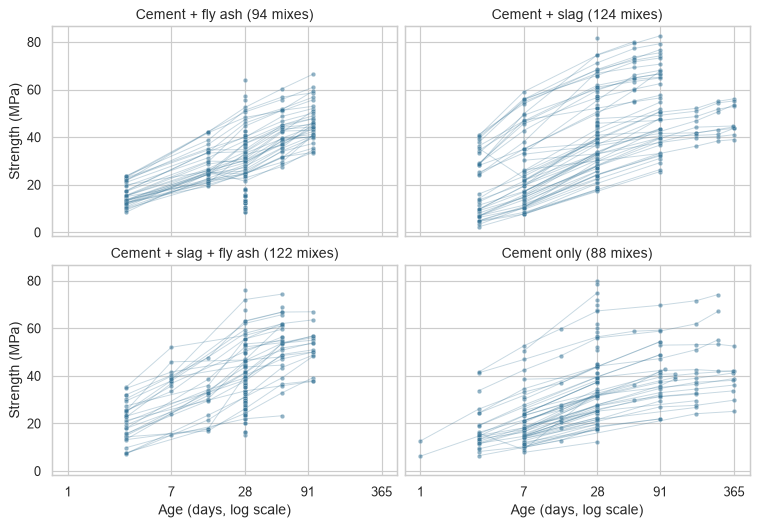

In [4]:
slag = series["blast_furnace_slag"] > 0
ash = series["fly_ash"] > 0
series["binder"] = np.select(
    [slag & ash, slag, ash],
    ["Cement + slag + fly ash", "Cement + slag", "Cement + fly ash"],
    default="Cement only",
)
fig, axes = plt.subplots(2, 2, figsize=(8.7, 6), sharex=True, sharey=True, layout="constrained")
for (label, subset), axis in zip(series.groupby("binder"), axes.flat, strict=True):
    repeated = subset[subset["mix_id"].isin(age_counts[age_counts > 1].index)]
    sns.scatterplot(subset, x="age_days", y=TARGET, s=14, alpha=0.55, ax=axis, color="#397698")
    sns.lineplot(
        repeated,
        x="age_days",
        y=TARGET,
        units="mix_id",
        estimator=None,
        color="#397698",
        alpha=0.28,
        linewidth=0.8,
        ax=axis,
    )
    count = subset["mix_id"].nunique()
    axis.set(
        xscale="log",
        xlabel="Age (days, log scale)",
        ylabel="Strength (MPa)",
        title=f"{label} ({count} mixes)",
    )
    axis.set_xticks([1, 7, 28, 91, 365], labels=["1", "7", "28", "91", "365"])
plt.show()

Each line connects measurements from one exact formulation. Single-age measurements
appear as points. Strength generally rises within a mix as it ages. Mix proportions, recorded ages
and unobserved curing or source conditions vary across binder categories, which limits
interpretation of differences between panels.